# DSP Mini-Project Member 1 - Vidyashankar T : CWRU Bearing Signal Analysis

**Scope:** CWRU data loading, bearing kinematic frequencies, signal preprocessing, baseline FFT/STFT, spectral window comparison, and multi load comparison for inner race, ball, and outer race faults.

**Dataset:** [CWRU Bearing NumPy repository](https://github.com/srigas/CWRU_Bearing_NumPy). The code analyses 12 comparable DE12 records: 7 mil defects, drive end channel, 12 kHz sampling, four motor speeds (1797, 1772, 1750, and 1730 RPM). The outer race defect is selected at the 6 o'clock position.

## 1. Environment and imports

In [ ]:
from pathlib import Path
import re
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

OUTPUT_DIR = Path("outputs/CWRU_Member1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Output directory:", OUTPUT_DIR.resolve())

Working directory: /content
Output directory: /content/outputs/CWRU_Member1


## 2. Download and locate the CWRU dataset

In [ ]:
REPOSITORY_URL = "https://github.com/srigas/CWRU_Bearing_NumPy.git"
DATA_ROOT = Path("datasets/CWRU_Bearing_NumPy")

if not DATA_ROOT.exists():
    DATA_ROOT.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run(
        ["git", "clone", REPOSITORY_URL, str(DATA_ROOT)],
        check=True
    )
else:
    print("CWRU repository already exists; skipping download.")

if not DATA_ROOT.exists():
    raise FileNotFoundError(f"CWRU dataset folder not found: {DATA_ROOT}")

npz_files = sorted(DATA_ROOT.rglob("*.npz"))
print("CWRU .npz files found:", len(npz_files))
if not npz_files:
    raise FileNotFoundError("No .npz files found. Check the repository download.")

CWRU .npz files found: 161


## 3. Bearing geometry and theoretical fault frequencies

For the CWRU SKF 6205 drive-end bearing, the geometry used here is:

- Number of rolling elements: 9
- Rolling-element diameter: 7.94 mm
- Pitch diameter: 39.04 mm
- Contact angle: 0°

The characteristic frequencies are calculated from shaft speed. They are **theoretical reference frequencies**, not measured spectral peaks.

In [ ]:
# CWRU SKF 6205 drive-end bearing geometry
N_ROLLING = 9
BALL_DIAMETER_MM = 7.94
PITCH_DIAMETER_MM = 39.04
CONTACT_ANGLE_DEG = 0.0


def kinematic_fault_frequencies(rpm):
    """Return ideal BPFO, BPFI, BSF and FTF in Hz for the CWRU 6205 bearing."""
    rpm = float(rpm)
    if not np.isfinite(rpm) or rpm <= 0:
        raise ValueError("RPM must be a positive finite value.")

    shaft_rate_hz = rpm / 60.0
    ratio = (BALL_DIAMETER_MM / PITCH_DIAMETER_MM) * np.cos(
        np.deg2rad(CONTACT_ANGLE_DEG)
    )

    return {
        "BPFO_Hz": (N_ROLLING / 2) * shaft_rate_hz * (1 - ratio),
        "BPFI_Hz": (N_ROLLING / 2) * shaft_rate_hz * (1 + ratio),
        "BSF_Hz": (PITCH_DIAMETER_MM / (2 * BALL_DIAMETER_MM)) * shaft_rate_hz * (1 - ratio**2),
        "FTF_Hz": (shaft_rate_hz / 2) * (1 - ratio),
        "shaft_rate_Hz": shaft_rate_hz,
        "shaft_rpm": rpm,
    }


LOAD_TO_RPM = {0: 1797, 1: 1772, 2: 1750, 3: 1730}
frequency_rows = []
for load_hp, rpm in LOAD_TO_RPM.items():
    frequency_rows.append({"Load_HP": load_hp, "RPM": rpm, **kinematic_fault_frequencies(rpm)})

cwru_frequency_table = pd.DataFrame(frequency_rows)
display(cwru_frequency_table.round(3))

,Load_HP,RPM,BPFO_Hz,BPFI_Hz,BSF_Hz,FTF_Hz,shaft_rate_Hz,shaft_rpm
0,0,1797,107.364,162.186,70.585,11.929,29.950,1797.0
1,1,1772,105.871,159.929,69.603,11.763,29.533,1772.0
2,2,1750,104.556,157.944,68.738,11.617,29.167,1750.0
3,3,1730,103.361,156.139,67.953,11.485,28.833,1730.0


At 1797 RPM, the calculated BPFO and BPFI are approximately 107.36 Hz and 162.19 Hz. As shaft speed decreases with increasing motor load in these recordings, the corresponding theoretical fault frequencies decrease proportionally.

## 4. Discrete-time fault signal model

A localized bearing defect can be represented as a sequence of impacts exciting the bearing housing resonance:

\[
x(t)=\sum_m A_m h(t-t_m)+w(t), \qquad t_m\approx\frac{m}{f_{\mathrm{fault}}}+\epsilon_m,
\]

where \(A_m\) is impact amplitude, \(h(t)\) is the structural impulse response, \(w(t)\) is background vibration/noise, and \(\epsilon_m\) represents timing variation such as slip. A simple damped resonant response is

\[
h(t)=e^{-\sigma t}\cos(2\pi f_r t)u(t).
\]

After sampling at \(f_s\),

\[
x[n]=\sum_m A_m h[n-n_m]+w[n].
\]

The baseline FFT and STFT characterize the measured signal. They do not perform resonance demodulation or make a fault decision; those are later project stages.

## 5. Signal loading and DSP helper functions

In [ ]:
SAMPLING_RATE_HZ = 12_000.0
WINDOWS = ("boxcar", "hann", "blackman")
WINDOW_LABELS = {
    "boxcar": "Rectangular",
    "hann": "Hann",
    "blackman": "Blackman",
}


def load_cwru_de12(path):
    """Load the Drive-End channel from a CWRU DE12 .npz record."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    with np.load(path, allow_pickle=False) as archive:
        if "DE" not in archive.files:
            raise KeyError(f"DE channel not found in {path.name}; keys: {archive.files}")
        x = np.asarray(archive["DE"], dtype=np.float64).squeeze()
    if x.ndim != 1 or x.size < 16 or not np.all(np.isfinite(x)):
        raise ValueError(f"Invalid signal array in {path.name}: shape={x.shape}")
    return x


def preprocess_signal(x):
    """Remove the DC mean and return signal plus amplitude statistics."""
    x = np.asarray(x, dtype=np.float64).squeeze()
    if x.ndim != 1 or x.size < 16 or not np.all(np.isfinite(x)):
        raise ValueError("Expected a finite one-dimensional signal of at least 16 samples.")
    dc_offset = float(np.mean(x))
    demeaned = x - dc_offset
    rms = float(np.sqrt(np.mean(demeaned**2)))
    peak = float(np.max(np.abs(demeaned)))
    normalized = demeaned / rms if rms > np.finfo(float).eps else demeaned.copy()
    stats = {"dc_offset": dc_offset, "rms": rms, "peak": peak}
    return demeaned, normalized, stats


def single_sided_amplitude_spectrum(x, fs, window="hann", nfft=None):
    """Coherent-gain-corrected one-sided amplitude spectrum."""
    x = np.asarray(x, dtype=np.float64).squeeze()
    if x.ndim != 1 or x.size < 16:
        raise ValueError("Expected a one-dimensional signal with at least 16 samples.")
    if window not in WINDOWS:
        raise ValueError(f"Window must be one of {WINDOWS}.")
    if nfft is None:
        nfft = x.size
    if nfft < x.size:
        raise ValueError("nfft must be >= signal length.")

    x = x - np.mean(x)
    w = signal.get_window(window, x.size, fftbins=True)
    scale = np.sum(w)
    spectrum = np.abs(np.fft.rfft(x * w, n=int(nfft))) / scale
    if int(nfft) % 2 == 0:
        if spectrum.size > 2:
            spectrum[1:-1] *= 2
    elif spectrum.size > 1:
        spectrum[1:] *= 2
    frequencies = np.fft.rfftfreq(int(nfft), d=1 / float(fs))
    return frequencies, spectrum


def compute_stft(x, fs, window="hann", nperseg=1024, noverlap=512):
    """Return frequency, time and complex STFT arrays."""
    x = np.asarray(x, dtype=np.float64).squeeze()
    if x.ndim != 1 or x.size < 16:
        raise ValueError("Expected a one-dimensional signal with at least 16 samples.")
    nperseg = min(int(nperseg), x.size)
    noverlap = min(int(noverlap), nperseg - 1)
    return signal.stft(
        x - np.mean(x), fs=float(fs), window=window,
        nperseg=nperseg, noverlap=noverlap,
        boundary=None, padded=False, detrend=False,
        return_onesided=True
    )

## 6. CWRU dataset inventory

In [ ]:
def parse_cwru_filename(path):
    name = Path(path).stem
    rpm_match = re.search(r"(?<!\d)(1797|1772|1750|1730)(?!\d)", name)
    rpm = int(rpm_match.group(1)) if rpm_match else None

    if "normal" in name.lower():
        fault = "Normal"
    elif "_IR_" in name:
        fault = "Inner race"
    elif "_B_" in name:
        fault = "Ball"
    elif "_OR@" in name:
        fault = "Outer race"
    else:
        fault = "Unknown"

    size_match = re.search(r"(?:IR|B|OR@\d+)_(\d+)(?:_|$)", name)
    pos_match = re.search(r"OR@(\d+)", name)
    rate_match = re.search(r"DE(12|48)(?:_|$)", name)

    return {
        "file": Path(path).name,
        "rpm": rpm,
        "fault": fault,
        "defect_diameter_mil": int(size_match.group(1)) if size_match else None,
        "outer_race_position": int(pos_match.group(1)) if pos_match else None,
        "DE_sampling_rate_hz": int(rate_match.group(1)) * 1000 if rate_match else None,
        "path": str(path),
    }


manifest = [parse_cwru_filename(p) for p in npz_files]
manifest = [row for row in manifest if row["rpm"] is not None]
cwru_inventory = pd.DataFrame(manifest)
print("CWRU records in manifest:", len(cwru_inventory))
display(pd.crosstab(cwru_inventory["fault"], cwru_inventory["rpm"]))

fault_7mil_inventory = cwru_inventory[
    cwru_inventory["defect_diameter_mil"] == 7
]
print("7-mil records by fault and RPM:")
display(pd.crosstab(fault_7mil_inventory["fault"], fault_7mil_inventory["rpm"]))

CWRU records in manifest: 161


rpm,1730,1750,1772,1797
fault,,,,
Ball,10,10,10,10
Inner race,10,10,10,10
Normal,1,1,1,1
Outer race,19,19,19,20


7-mil records by fault and RPM:


rpm,1730,1750,1772,1797
fault,,,,
Ball,3,3,3,3
Inner race,3,3,3,3
Outer race,9,9,9,9


## 7. Select comparable CWRU records

To make a controlled comparison, the selected records use the same:

- Defect size: 7 mil
- Sensor channel: Drive End (`DE`)
- Sampling rate: 12 kHz (`DE12`)
- Motor speeds: 1797, 1772, 1750 and 1730 RPM

The selected outer race defect is at the 6 o'clock position. This gives 12 records in total: four for each fault type.

In [ ]:
RPM_VALUES = [1797, 1772, 1750, 1730]
FAULT_SPECS = {
    "Inner Race": "IR_7",
    "Ball": "B_7",
    "Outer Race (6 o'clock)": "OR@6_7",
}

selected_paths = {}
missing_files = []
for fault_name, code in FAULT_SPECS.items():
    selected_paths[fault_name] = {}
    for rpm in RPM_VALUES:
        filename = f"{rpm}_{code}_DE12.npz"
        matches = list(DATA_ROOT.rglob(filename))
        if len(matches) != 1:
            missing_files.append(filename)
        else:
            selected_paths[fault_name][rpm] = matches[0]

if missing_files:
    raise FileNotFoundError("Missing or ambiguous selected files: " + ", ".join(missing_files))

print("Selected records:", sum(len(v) for v in selected_paths.values()))
for fault_name, files_by_rpm in selected_paths.items():
    print(f"{fault_name}: {len(files_by_rpm)} records")

Selected records: 12
Inner Race: 4 records
Ball: 4 records
Outer Race (6 o'clock): 4 records


## 8. Load the 12 selected vibration records

In [ ]:
records_by_fault = {}
metadata_rows = []

for fault_name, files_by_rpm in selected_paths.items():
    records_by_fault[fault_name] = {}
    for rpm, path in files_by_rpm.items():
        x = load_cwru_de12(path)
        record = {
            "signal": x,
            "sampling_rate_hz": SAMPLING_RATE_HZ,
            "rpm": rpm,
            "load_hp": {1797: 0, 1772: 1, 1750: 2, 1730: 3}[rpm],
            "fault": fault_name,
            "path": str(path),
        }
        records_by_fault[fault_name][rpm] = record
        metadata_rows.append({
            "Fault": fault_name,
            "Load_HP": record["load_hp"],
            "RPM": rpm,
            "Filename": path.name,
            "Samples": len(x),
            "Sampling_Rate_Hz": SAMPLING_RATE_HZ,
            "Duration_s": len(x) / SAMPLING_RATE_HZ,
        })

cwru_metadata_df = pd.DataFrame(metadata_rows).sort_values(["Fault", "Load_HP"])
display(cwru_metadata_df)
assert len(cwru_metadata_df) == 12
assert cwru_metadata_df["Sampling_Rate_Hz"].eq(12000).all()

,Fault,Load_HP,RPM,Filename,Samples,Sampling_Rate_Hz,Duration_s
4,Ball,0,1797,1797_B_7_DE12.npz,122571,12000.0,10.214250
5,Ball,1,1772,1772_B_7_DE12.npz,121410,12000.0,10.117500
6,Ball,2,1750,1750_B_7_DE12.npz,121556,12000.0,10.129667
7,Ball,3,1730,1730_B_7_DE12.npz,121556,12000.0,10.129667
0,Inner Race,0,1797,1797_IR_7_DE12.npz,121265,12000.0,10.105417
1,Inner Race,1,1772,1772_IR_7_DE12.npz,121991,12000.0,10.165917
2,Inner Race,2,1750,1750_IR_7_DE12.npz,122136,12000.0,10.178000
3,Inner Race,3,1730,1730_IR_7_DE12.npz,122917,12000.0,10.243083
8,Outer Race (6 o'clock),0,1797,1797_OR@6_7_DE12.npz,121991,12000.0,10.165917
9,Outer Race (6 o'clock),1,1772,1772_OR@6_7_DE12.npz,122426,12000.0,10.202167


## 9. Representative-record preprocessing (1797 RPM, inner-race fault)

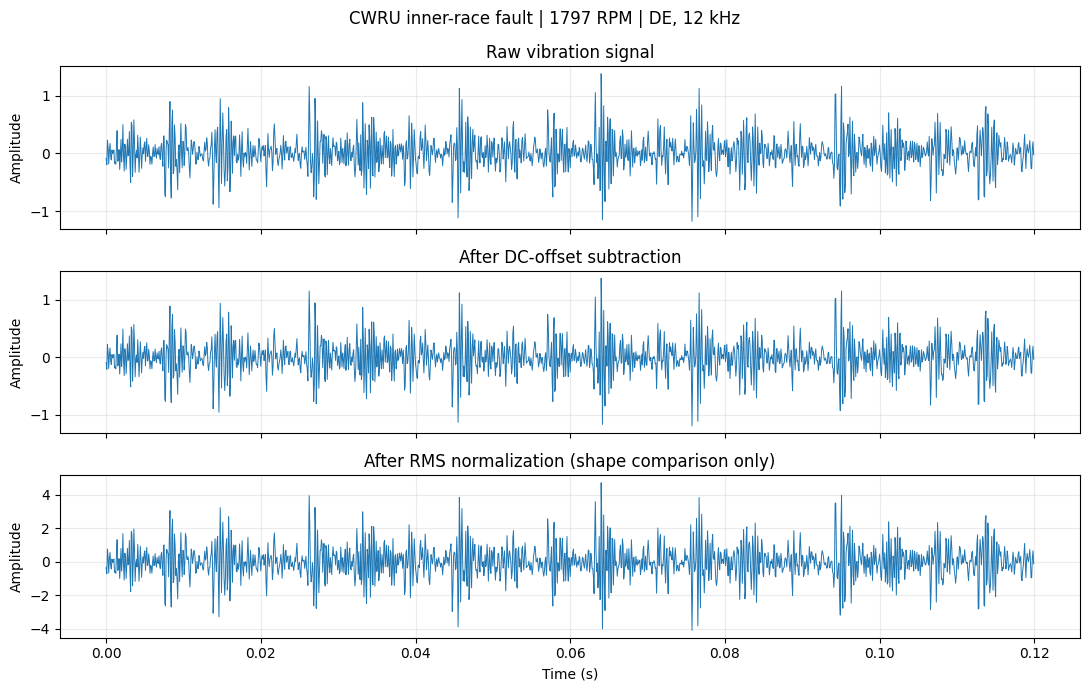

Preprocessing statistics: {'dc_offset': 0.013443559443270714, 'rms': 0.2912159093347009, 'peak': 1.7255869395587253}


In [ ]:
representative = records_by_fault["Inner Race"][1797]
x_raw = representative["signal"]
x_demeaned, x_rms_normalized, representative_stats = preprocess_signal(x_raw)

n_plot = int(0.12 * SAMPLING_RATE_HZ)
time_axis = np.arange(n_plot) / SAMPLING_RATE_HZ

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].plot(time_axis, x_raw[:n_plot], linewidth=0.7)
axes[0].set_title("Raw vibration signal")
axes[1].plot(time_axis, x_demeaned[:n_plot], linewidth=0.7)
axes[1].set_title("After DC-offset subtraction")
axes[2].plot(time_axis, x_rms_normalized[:n_plot], linewidth=0.7)
axes[2].set_title("After RMS normalization (shape comparison only)")
axes[2].set_xlabel("Time (s)")
for ax in axes:
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.25)
fig.suptitle("CWRU inner-race fault | 1797 RPM | DE, 12 kHz")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "A1_CWRU_preprocessing.png", dpi=250, bbox_inches="tight")
plt.show()
print("Preprocessing statistics:", representative_stats)

## 10. Baseline FFT of the representative CWRU record

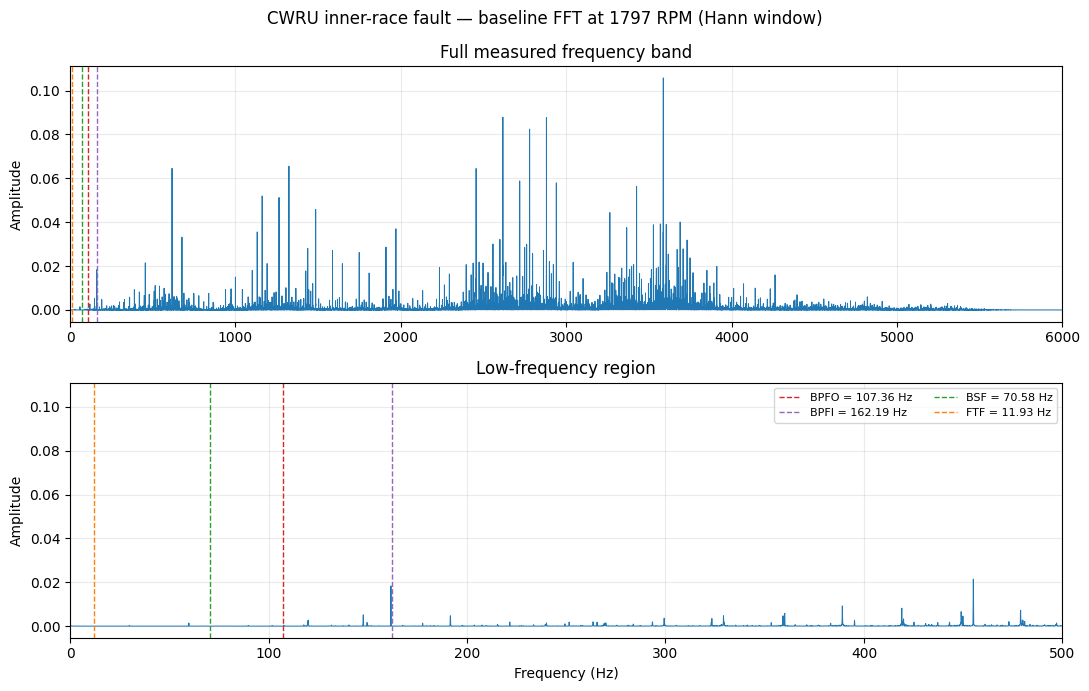

In [ ]:
frequencies, amplitude = single_sided_amplitude_spectrum(
    x_demeaned, SAMPLING_RATE_HZ, window="hann"
)
reference_freqs = kinematic_fault_frequencies(1797)

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
axes[0].plot(frequencies, amplitude, linewidth=0.7)
axes[0].set_xlim(0, SAMPLING_RATE_HZ / 2)
axes[0].set_title("Full measured frequency band")
axes[0].set_ylabel("Amplitude")
axes[1].plot(frequencies, amplitude, linewidth=0.7)
axes[1].set_xlim(0, 500)
axes[1].set_title("Low-frequency region")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Amplitude")
colors = {"BPFO_Hz": "tab:red", "BPFI_Hz": "tab:purple", "BSF_Hz": "tab:green", "FTF_Hz": "tab:orange"}
for name, value in reference_freqs.items():
    if name in colors:
        for ax in axes:
            if value <= ax.get_xlim()[1]:
                ax.axvline(value, linestyle="--", linewidth=1, color=colors[name], label=f"{name.replace('_Hz','')} = {value:.2f} Hz")
axes[1].legend(fontsize=8, ncol=2)
for ax in axes:
    ax.grid(alpha=0.25)
fig.suptitle("CWRU inner-race fault — baseline FFT at 1797 RPM (Hann window)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "A2_CWRU_baseline_FFT.png", dpi=250, bbox_inches="tight")
plt.show()

The dashed lines indicate ideal kinematic reference frequencies. The baseline FFT shows the measured raw spectrum; it should not be treated as a completed fault detector. A weak defect repetition component can be obscured by other vibration components, motivating the later resonance selection and envelope demodulation stages.

## 11. Spectral leakage: window comparison

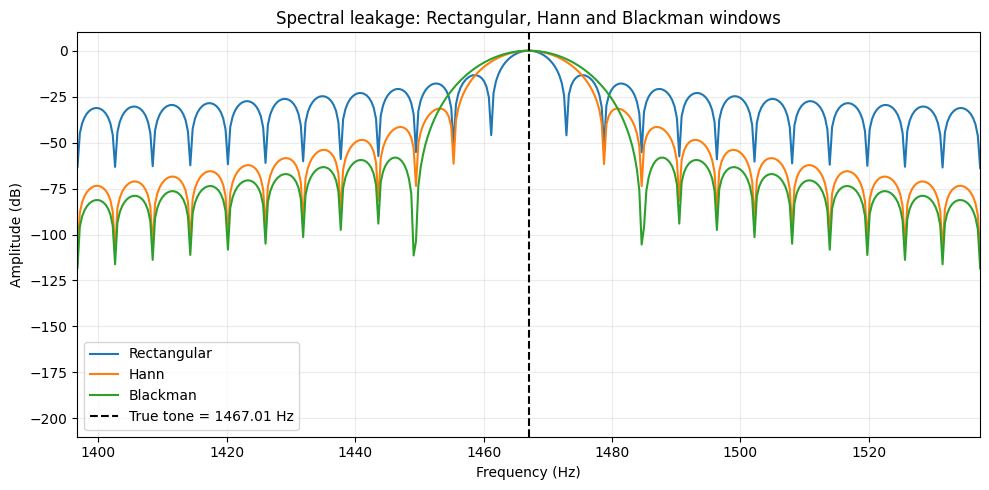

,Window,Approx_Leakage_Energy_Fraction
0,Rectangular,0.066135
1,Hann,0.000176
2,Blackman,0.000003


In [ ]:
# Controlled off-bin sinusoid used only to demonstrate the effect of finite-window leakage.
fs_demo = 12_000.0
n_demo = 2048
tone_bin = 250
fractional_offset = 0.37
f0 = (tone_bin + fractional_offset) * fs_demo / n_demo
n = np.arange(n_demo)
x_tone = np.sin(2 * np.pi * f0 * n / fs_demo)

leakage_rows = []
fig, ax = plt.subplots(figsize=(10, 5))
for window in WINDOWS:
    f, a = single_sided_amplitude_spectrum(
        x_tone, fs_demo, window=window, nfft=n_demo * 16
    )
    ax.plot(f, 20 * np.log10(np.maximum(a, 1e-10)), label=WINDOW_LABELS[window])

    half_widths = {"boxcar": 1.5, "hann": 2.5, "blackman": 3.5}
    peak = int(np.argmax(a))
    half = int(np.ceil(half_widths[window] * 16))
    mask = np.zeros(a.size, dtype=bool)
    mask[max(0, peak-half):min(a.size, peak+half+1)] = True
    energy = a**2
    leakage_rows.append({
        "Window": WINDOW_LABELS[window],
        "Approx_Leakage_Energy_Fraction": float(np.sum(energy[~mask]) / np.sum(energy)),
    })

ax.axvline(f0, color="black", linestyle="--", label=f"True tone = {f0:.2f} Hz")
ax.set_xlim(f0 - 12 * fs_demo / n_demo, f0 + 12 * fs_demo / n_demo)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Amplitude (dB)")
ax.set_title("Spectral leakage: Rectangular, Hann and Blackman windows")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "A3_spectral_leakage_windows.png", dpi=250, bbox_inches="tight")
plt.show()

display(pd.DataFrame(leakage_rows).round(8))

The leakage graph is a **controlled synthetic demonstration**, not a bearing measurement. It isolates how the observation window changes sidelobes and main lobe width. The reported leakage fraction is an approximate educational metric based on excluding a window specific main lobe region.

## 12. STFT comparison for the representative CWRU record

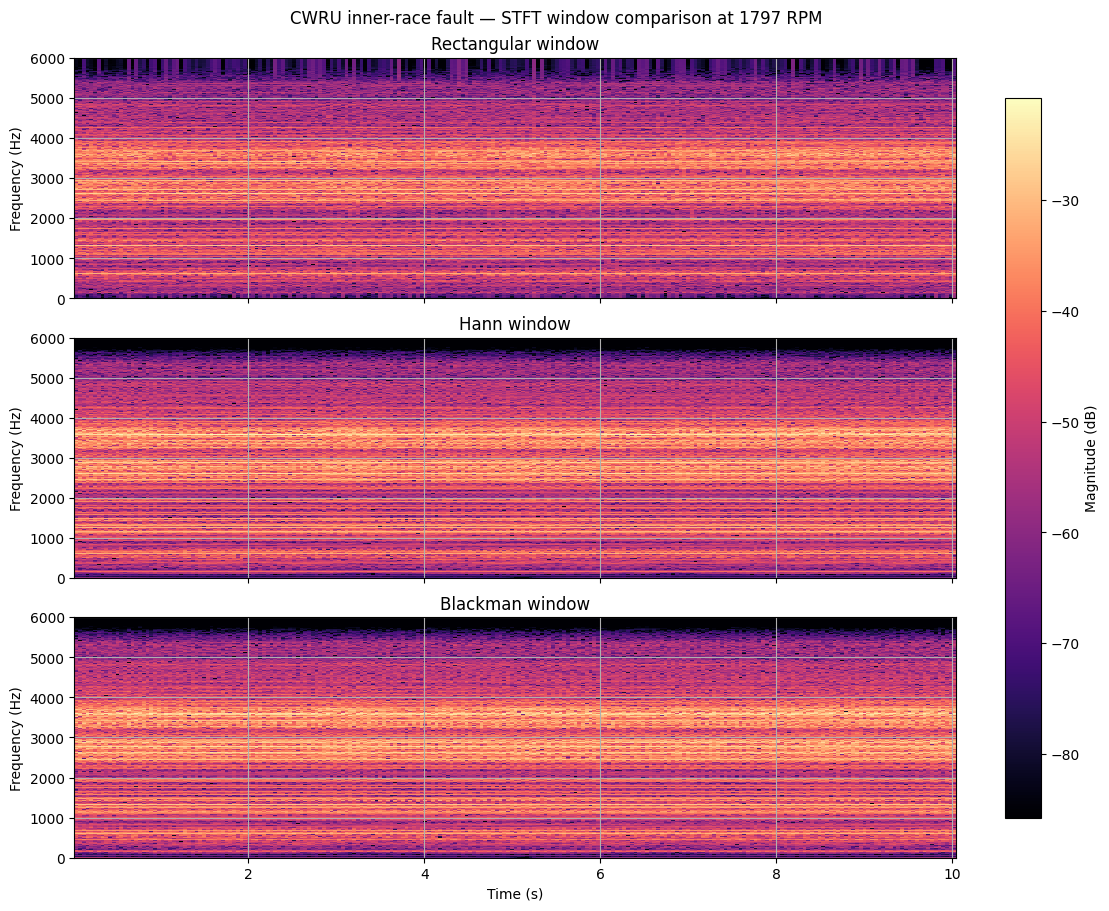

In [ ]:
stft_results = []
for window in WINDOWS:
    f, t_stft, z = compute_stft(
        x_demeaned, SAMPLING_RATE_HZ,
        window=window, nperseg=1024, noverlap=512
    )
    magnitude_db = 20 * np.log10(np.maximum(np.abs(z), 1e-12))
    stft_results.append((window, f, t_stft, magnitude_db))

shared_max = max(float(np.max(item[3])) for item in stft_results)
vmin, vmax = shared_max - 65, shared_max
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, sharey=True, constrained_layout=True)
mesh = None
for ax, (window, f, t_stft, magnitude_db) in zip(axes, stft_results):
    mesh = ax.pcolormesh(
        t_stft, f, magnitude_db, shading="auto", cmap="magma",
        vmin=vmin, vmax=vmax
    )
    ax.set_ylim(0, SAMPLING_RATE_HZ / 2)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_title(f"{WINDOW_LABELS[window]} window")
axes[-1].set_xlabel("Time (s)")
fig.colorbar(mesh, ax=axes, label="Magnitude (dB)", shrink=0.9)
fig.suptitle("CWRU inner-race fault — STFT window comparison at 1797 RPM")
fig.savefig(OUTPUT_DIR / "A4_CWRU_STFT_windows.png", dpi=250, bbox_inches="tight")
plt.show()

## 13. Inner-race FFT across four motor loads

The same 7 mil inner race defect and DE12 channel are compared at 0, 1, 2 and 3 HP. Dashed lines mark the theoretical BPFI for each shaft speed.

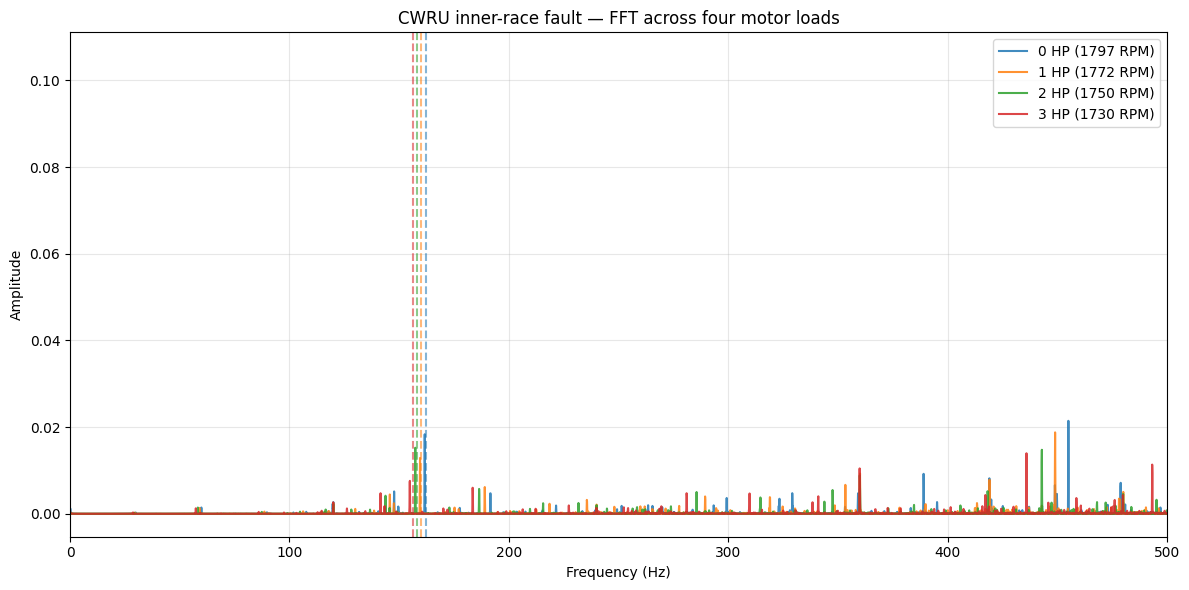

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
for rpm in RPM_VALUES:
    rec = records_by_fault["Inner Race"][rpm]
    x, _, _ = preprocess_signal(rec["signal"])
    f, a = single_sided_amplitude_spectrum(x, SAMPLING_RATE_HZ, window="hann")
    line, = ax.plot(f, a, label=f"{rec['load_hp']} HP ({rpm} RPM)", alpha=0.85)
    bpfi = kinematic_fault_frequencies(rpm)["BPFI_Hz"]
    ax.axvline(bpfi, color=line.get_color(), linestyle="--", alpha=0.55)

ax.set_xlim(0, 500)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Amplitude")
ax.set_title("CWRU inner-race fault — FFT across four motor loads")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "A5_CWRU_inner_race_FFT_four_loads.png", dpi=250, bbox_inches="tight")
plt.show()

## 14. FFT comparison across three fault types and four loads

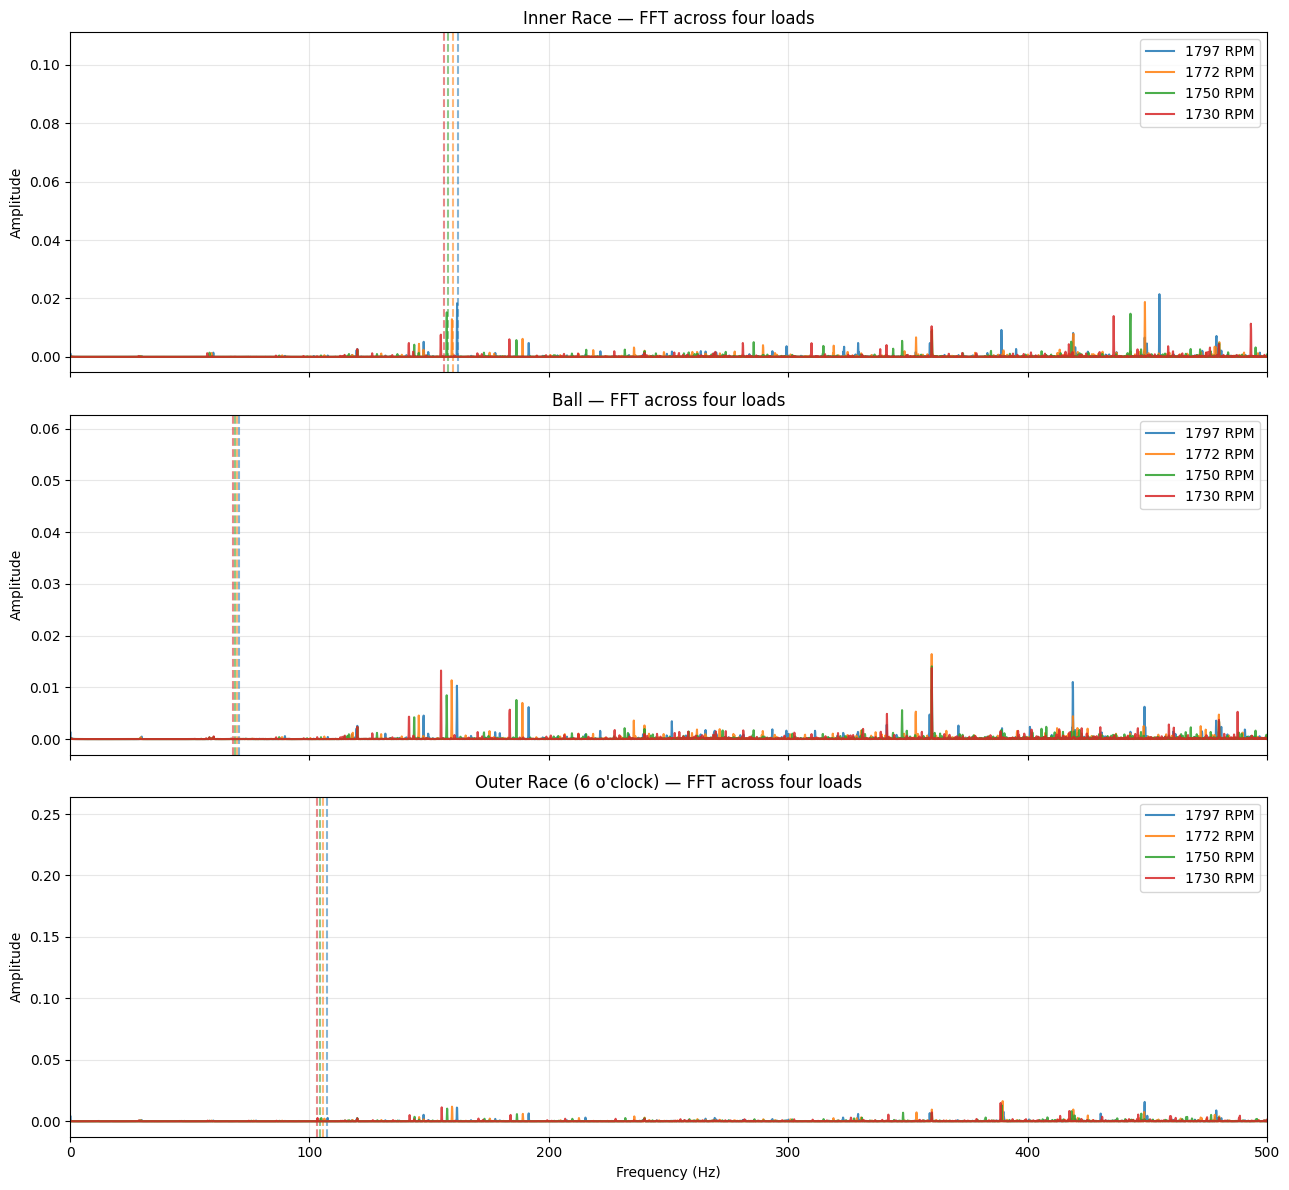

In [ ]:
fault_frequency_key = {
    "Inner Race": "BPFI_Hz",
    "Ball": "BSF_Hz",
    "Outer Race (6 o'clock)": "BPFO_Hz",
}

fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for ax, (fault_name, fault_records) in zip(axes, records_by_fault.items()):
    target_key = fault_frequency_key[fault_name]
    for rpm in RPM_VALUES:
        rec = fault_records[rpm]
        x, _, _ = preprocess_signal(rec["signal"])
        f, a = single_sided_amplitude_spectrum(x, SAMPLING_RATE_HZ, window="hann")
        line, = ax.plot(f, a, label=f"{rpm} RPM", alpha=0.85)
        target = kinematic_fault_frequencies(rpm)[target_key]
        ax.axvline(target, color=line.get_color(), linestyle="--", alpha=0.55)
    ax.set_xlim(0, 500)
    ax.set_ylabel("Amplitude")
    ax.set_title(f"{fault_name} — FFT across four loads")
    ax.legend()
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Frequency (Hz)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "A6_CWRU_three_faults_four_loads.png", dpi=250, bbox_inches="tight")
plt.show()

## 15. Experimental summary table

In [ ]:
fault_frequency_key = {
    "Inner Race": "BPFI_Hz",
    "Ball": "BSF_Hz",
    "Outer Race (6 o'clock)": "BPFO_Hz",
}

result_rows = []
for fault_name, fault_records in records_by_fault.items():
    for rpm, rec in fault_records.items():
        x, _, stats = preprocess_signal(rec["signal"])
        characteristic = kinematic_fault_frequencies(rpm)
        target_key = fault_frequency_key[fault_name]
        result_rows.append({
            "Fault": fault_name,
            "Load_HP": rec["load_hp"],
            "RPM": rpm,
            "Samples": len(x),
            "Sampling_Rate_Hz": SAMPLING_RATE_HZ,
            "Duration_s": len(x) / SAMPLING_RATE_HZ,
            "DC_Offset": stats["dc_offset"],
            "RMS": stats["rms"],
            "Peak": stats["peak"],
            "BPFO_Hz": characteristic["BPFO_Hz"],
            "BPFI_Hz": characteristic["BPFI_Hz"],
            "BSF_Hz": characteristic["BSF_Hz"],
            "FTF_Hz": characteristic["FTF_Hz"],
            "Target_Fault_Frequency_Hz": characteristic[target_key],
        })

cwru_results_df = pd.DataFrame(result_rows).sort_values(["Fault", "Load_HP"])
display(cwru_results_df.round(4))

,Fault,Load_HP,RPM,Samples,Sampling_Rate_Hz,Duration_s,DC_Offset,RMS,Peak,BPFO_Hz,BPFI_Hz,BSF_Hz,FTF_Hz,Target_Fault_Frequency_Hz
4,Ball,0,1797,122571,12000.0,10.2142,0.0126,0.1387,0.6196,107.3643,162.1857,70.5846,11.9294,70.5846
5,Ball,1,1772,121410,12000.0,10.1175,0.0039,0.1390,0.6635,105.8706,159.9294,69.6026,11.7634,69.6026
6,Ball,2,1750,121556,12000.0,10.1297,0.0046,0.1472,0.6000,104.5562,157.9438,68.7385,11.6174,68.7385
7,Ball,3,1730,121556,12000.0,10.1297,0.0042,0.1536,0.7248,103.3613,156.1387,67.9529,11.4846,67.9529
0,Inner Race,0,1797,121265,12000.0,10.1054,0.0134,0.2912,1.7256,107.3643,162.1857,70.5846,11.9294,162.1857
1,Inner Race,1,1772,121991,12000.0,10.1659,0.0058,0.2928,1.5750,105.8706,159.9294,69.6026,11.7634,159.9294
2,Inner Race,2,1750,122136,12000.0,10.1780,0.0046,0.2995,1.6351,104.5562,157.9438,68.7385,11.6174,157.9438
3,Inner Race,3,1730,122917,12000.0,10.2431,0.0047,0.3136,1.6667,103.3613,156.1387,67.9529,11.4846,156.1387
8,Outer Race (6 o'clock),0,1797,121991,12000.0,10.1659,0.0232,0.6691,3.6073,107.3643,162.1857,70.5846,11.9294,107.3643
9,Outer Race (6 o'clock),1,1772,122426,12000.0,10.2022,0.0041,0.5919,3.1082,105.8706,159.9294,69.6026,11.7634,105.8706


## 16. RMS vibration amplitude across motor loads

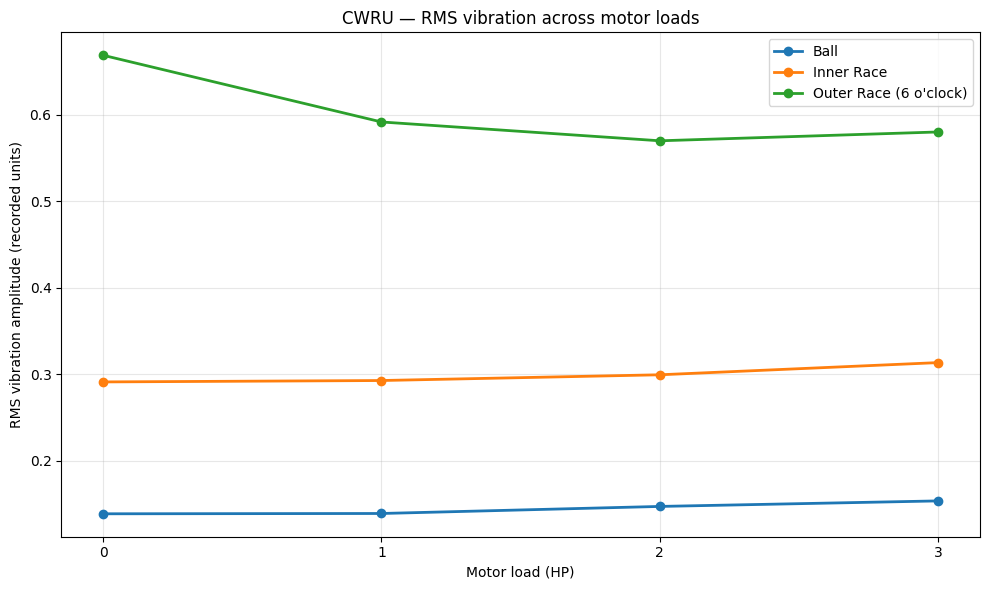

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
for fault_name in cwru_results_df["Fault"].unique():
    subset = cwru_results_df[cwru_results_df["Fault"] == fault_name].sort_values("Load_HP")
    ax.plot(
        subset["Load_HP"], subset["RMS"],
        marker="o", linewidth=2, label=fault_name
    )

ax.set_xlabel("Motor load (HP)")
ax.set_ylabel("RMS vibration amplitude (recorded units)")
ax.set_title("CWRU — RMS vibration across motor loads")
ax.set_xticks([0, 1, 2, 3])
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "A7_CWRU_RMS_vs_load.png", dpi=250, bbox_inches="tight")
plt.show()

## 17. Export tables and figures



In [ ]:
cwru_inventory_csv = OUTPUT_DIR / "CWRU_dataset_inventory.csv"
selected_metadata_csv = OUTPUT_DIR / "CWRU_selected_record_metadata.csv"
frequency_csv = OUTPUT_DIR / "CWRU_kinematic_frequency_table.csv"
results_csv = OUTPUT_DIR / "CWRU_experimental_results.csv"
leakage_csv = OUTPUT_DIR / "CWRU_window_leakage_metrics.csv"

cwru_inventory.to_csv(cwru_inventory_csv, index=False)
cwru_metadata_df.to_csv(selected_metadata_csv, index=False)
cwru_frequency_table.to_csv(frequency_csv, index=False)
cwru_results_df.to_csv(results_csv, index=False)
pd.DataFrame(leakage_rows).to_csv(leakage_csv, index=False)

print("Saved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name}: {path.stat().st_size:,} bytes")

Saved files:
A1_CWRU_preprocessing.png: 710,011 bytes
A2_CWRU_baseline_FFT.png: 228,262 bytes
A3_spectral_leakage_windows.png: 301,834 bytes
A4_CWRU_STFT_windows.png: 1,578,738 bytes
A5_CWRU_inner_race_FFT_four_loads.png: 174,342 bytes
A6_CWRU_three_faults_four_loads.png: 396,388 bytes
A7_CWRU_RMS_vs_load.png: 115,849 bytes
CWRU_dataset_inventory.csv: 17,624 bytes
CWRU_experimental_results.csv: 2,539 bytes
CWRU_kinematic_frequency_table.csv: 481 bytes
CWRU_selected_record_metadata.csv: 889 bytes
CWRU_window_leakage_metrics.csv: 130 bytes
